In [12]:
import os

import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import Image
import re
from wordfreq import zipf_frequency


sys.path.append("../src")
from surprisal import tok, lm, dev, full_surprisal, lossy_surprisal
from ns_data import load_stories
import surprisal

LAMS = [1, 2, 4, 8]

2(a) Full and lossy surprisals

In [2]:
SC_DIR = Path("../data/structuralcost")
sc = pd.concat([pd.read_csv(SC_DIR / "StructuralCost_critical.csv"),
                pd.read_csv(SC_DIR / "StructuralCost_control.csv")], ignore_index=True)
sc["split"] = sc["tag"].map({"exp-1": "critical", "exp-2": "control"})
sc["item"] = sc["split"] + "_" + sc["setID"].astype(str)
print(len(sc), "rows,", sc["sentID_in_dataset"].nunique(), "sentences")

595734 rows, 450 sentences


In [3]:
# one row per word of each sentence (every participant repeats them)
words = (sc[["sentID_in_dataset", "wordID", "word"]]
         .drop_duplicates()
         .sort_values(["sentID_in_dataset", "wordID"]))
assert not words.duplicated(["sentID_in_dataset", "wordID"]).any(), "same position, different words"

sentences = {s: g["word"].tolist() for s, g in words.groupby("sentID_in_dataset")}

# one row per sentence, with what we need about it
sents = (sc.drop_duplicates("sentID_in_dataset")
         [["sentID_in_dataset", "item", "split", "sentence_structure", "dep_length", "root_i"]]
         .reset_index(drop=True))
sents["verb"] = [sentences[s][i] for s, i in zip(sents["sentID_in_dataset"], sents["root_i"])]
sents["context"] = [sentences[s][:i] for s, i in zip(sents["sentID_in_dataset"], sents["root_i"])]

print(len(sents), "sentences")
for _, r in sents.sample(5, random_state=0).iterrows():
    print(f"{r['sentence_structure']:16} {' '.join(r['context'])} [{r['verb']}]")

450 sentences
baseline-1       The raindrops [cover]
standard-subject The sailor that called the navigator [unfolds]
nested-object    The detective that the witness that the abandoned warehouse housed questioned [catalogs]
nested-subject   The columnist that consulted the editor that was in the office [graces]
standard-object  The mother that the neighbor called [comforts]


In [ ]:
RUN_SURP = False

if RUN_SURP:
    t0 = time.time()
    rows = []
    for _, r in sents.iterrows():
        row = {"sentID_in_dataset": r["sentID_in_dataset"],
            "surp_full": full_surprisal(r["context"], r["verb"])}
        for lam in LAMS:
            # fixed seed for each sentence and lambda, as for Natural Stories
            surprisal.rng = np.random.default_rng([int(r["sentID_in_dataset"]), lam])
            row[f"surp_lam{lam}"] = lossy_surprisal(r["context"], r["verb"], lam=lam)
        rows.append(row)

    sc_surp = sents.drop(columns="context").merge(pd.DataFrame(rows), on="sentID_in_dataset")
    sc_surp.to_csv("../results/sc_surp.csv", index=False)
    print(f"{len(sc_surp)} verbs in {time.time() - t0:.0f} s")

In [7]:
sc_surp = pd.read_csv("../results/sc_surp.csv")

In [8]:
cols = ["surp_full"] + [f"surp_lam{lam}" for lam in LAMS]
print(sc_surp[cols].describe().round(2))
print(sc_surp.groupby(["split", "sentence_structure"])[cols].mean().round(2))

       surp_full  surp_lam1  surp_lam2  surp_lam4  surp_lam8
count     450.00     450.00     450.00     450.00     450.00
mean       17.80      20.87      18.94      18.25      18.20
std         4.25       3.69       3.63       3.67       3.78
min         8.58      13.10      11.44      10.95       9.89
25%        14.98      18.53      16.64      15.69      15.64
50%        17.31      20.32      18.39      17.64      17.73
75%        20.22      22.64      20.71      20.04      20.25
max        38.13      37.66      35.84      35.51      35.93
                             surp_full  surp_lam1  surp_lam2  surp_lam4  \
split    sentence_structure                                               
control  baseline-2              14.91      19.35      17.11      15.97   
         pp-long                 15.70      19.43      17.61      17.03   
         pp-short                14.74      19.71      17.44      16.33   
critical baseline-1              16.68      20.84      19.13      17.88   
 

In [9]:
print(sc_surp.groupby(["split", "sentence_structure"])["dep_length"].unique())

split     sentence_structure
control   baseline-2            [0]
          pp-long               [9]
          pp-short              [4]
critical  baseline-1            [0]
          control               [4]
          nested-object         [9]
          nested-subject        [9]
          standard-object       [4]
          standard-subject      [4]
Name: dep_length, dtype: object


2(b) Predicted surprisal vs distance

In [ ]:
ctrl = sc_surp[sc_surp["split"] == "control"]
means = ctrl.groupby("dep_length")[cols].mean()
sems = ctrl.groupby("dep_length")[cols].sem()      # standard error: how precise each mean is

print(means.round(2))
print("\nchange from distance 0 to 9:")
print((means.loc[9] - means.loc[0]).round(2))

            surp_full  surp_lam1  surp_lam2  surp_lam4  surp_lam8
dep_length                                                       
0               14.91      19.35      17.11      15.97      15.47
4               14.74      19.71      17.44      16.33      15.87
9               15.70      19.43      17.61      17.03      16.95

change from distance 0 to 9:
surp_full    0.79
surp_lam1    0.08
surp_lam2    0.50
surp_lam4    1.07
surp_lam8    1.48
dtype: float64


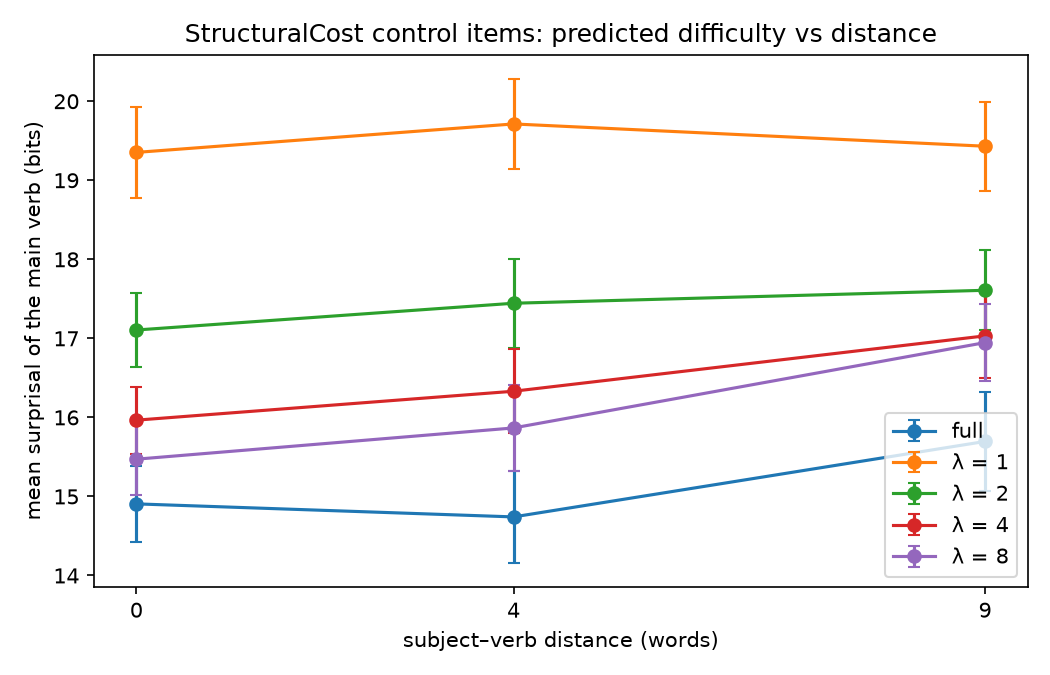

In [13]:
labels = {"surp_full": "full"} | {f"surp_lam{lam}": f"λ = {lam}" for lam in LAMS}

fig, ax = plt.subplots(figsize=(7, 4.5))
for c in cols:
    ax.errorbar(means.index, means[c], yerr=sems[c], marker="o", capsize=3, label=labels[c])
ax.set_xticks([0, 4, 9])
ax.set_xlabel("subject–verb distance (words)")
ax.set_ylabel("mean surprisal of the main verb (bits)")
ax.set_title("StructuralCost control items: predicted difficulty vs distance")
ax.legend()
plt.tight_layout()

plt.savefig("../figures/sc_control_distance.pdf")
plt.savefig("../figures/sc_control_distance.png", dpi=150)
plt.close(fig)
Image("../figures/sc_control_distance.png")